# Occipital fNIRS Activity-Based iTBS Triggering

Replication of `Motor_Cortex_iTBS_Analysis_Executed.ipynb` with occipital fNIRS data.

**Structure:** Peak/trough detection → categorization → iTBS triggers (activity-based, standard fixed, and peak/trough-based)

In [ ]:
TIME_WINDOW_SEC = 300
MIN_PEAK_DISTANCE_SEC = 5
ACTIVITY_THRESHOLD_PERCENTILE = 75
STANDARD_BURST_DURATION_SEC = 2
STANDARD_BURST_INTERVAL_SEC = 10

In [ ]:
import os
import glob
import numpy as np
import pandas as pd
import matplotlib.pyplot as plt
import warnings
warnings.filterwarnings('ignore')

plt.rcParams.update({
    'font.size': 20, 'axes.titlesize': 24, 'axes.labelsize': 22,
    'xtick.labelsize': 18, 'ytick.labelsize': 18, 'legend.fontsize': 16,
    'lines.linewidth': 3
})
print('✓ Configuration loaded')

✓ Configuration loaded


In [ ]:
PILOT_DIR = '/content/drive/MyDrive/Work/Writing/Grants/_Not_Awarded/2026__CIHR_Spring_fNIRS/pilot_analyses'
DATA_DIR = os.path.join(PILOT_DIR, 'ipd_batch_results')
csv_files = sorted(glob.glob(os.path.join(DATA_DIR, '*_dynamics.csv')))[:9]
print(f'Found {len(csv_files)} subject/session files')

Found 9 subject/session files


In [ ]:
def find_peaks_numpy(signal, distance):
    peaks = []
    for i in range(distance, len(signal) - distance):
        if signal[i] > signal[i-distance] and signal[i] > signal[i+distance]:
            peaks.append(i)
    filtered = []
    for p in peaks:
        if not filtered or p - filtered[-1] >= distance:
            filtered.append(p)
    return np.array(filtered)

def plot_categorized_markers(ax, t_sub, activity_sub, p_high, p_low, t_low, t_high, alpha=1.0):
    if len(p_high) > 0:
        ax.plot(t_sub[p_high], activity_sub[p_high], '^', color='red', markersize=10, alpha=alpha, label='Peak (Valid High Activity)')
    if len(p_low) > 0:
        ax.plot(t_sub[p_low], activity_sub[p_low], '^', color='blue', markersize=10, alpha=alpha, label='Peak (Invalid Low Activity)')
    if len(t_low) > 0:
        ax.plot(t_sub[t_low], activity_sub[t_low], 'v', color='blue', markersize=10, alpha=alpha, label='Trough (Valid Low Activity)')
    if len(t_high) > 0:
        ax.plot(t_sub[t_high], activity_sub[t_high], 'v', color='red', markersize=10, alpha=alpha, label='Trough (Invalid High Activity)')

print('✓ Helper functions defined')

✓ Helper functions defined


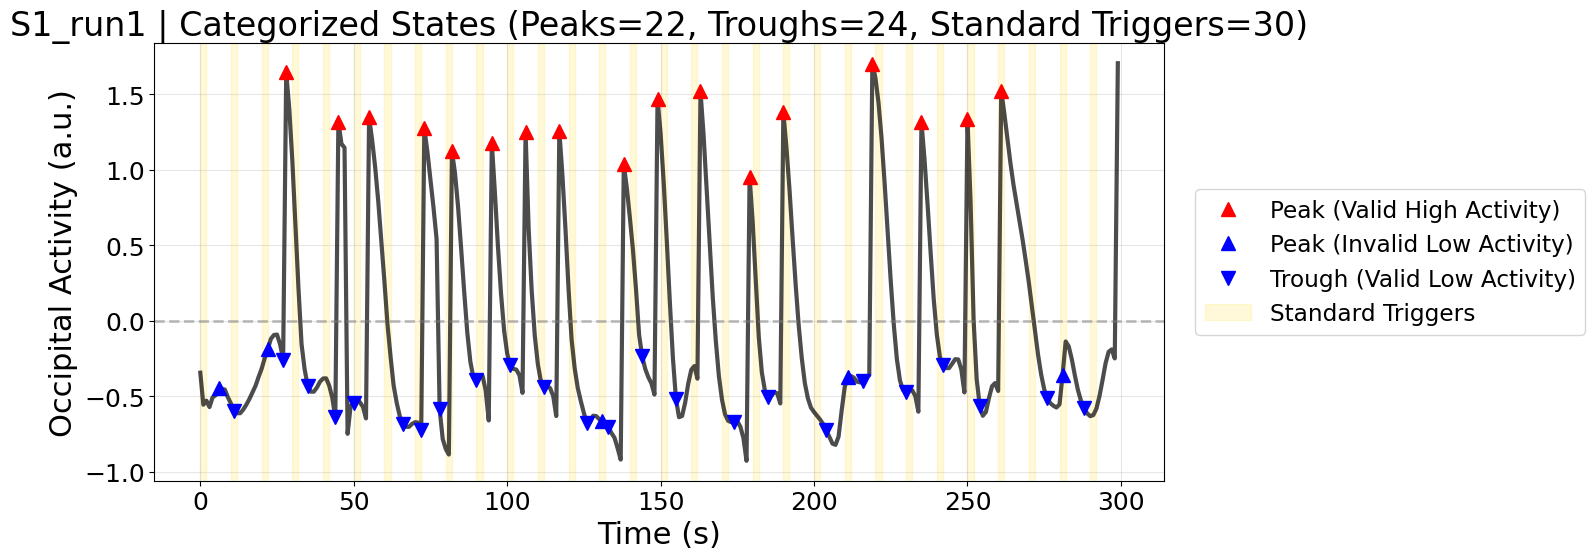

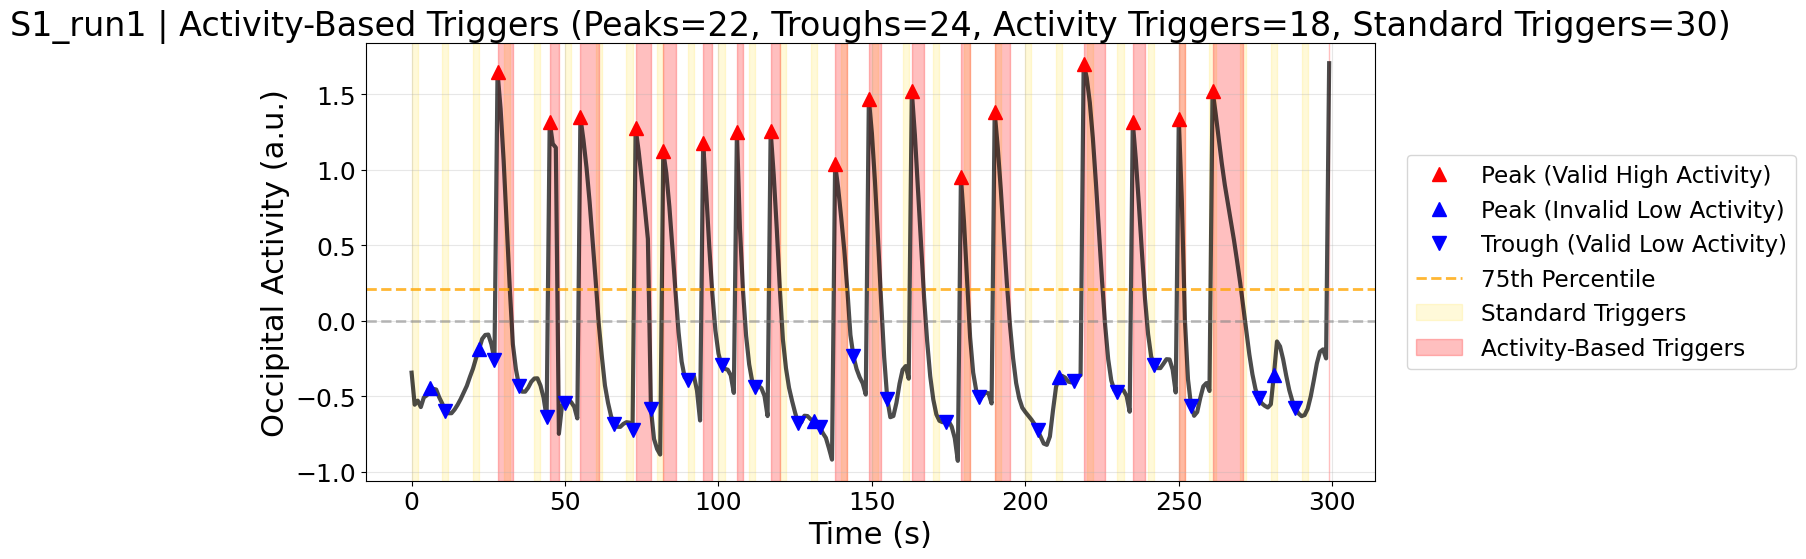

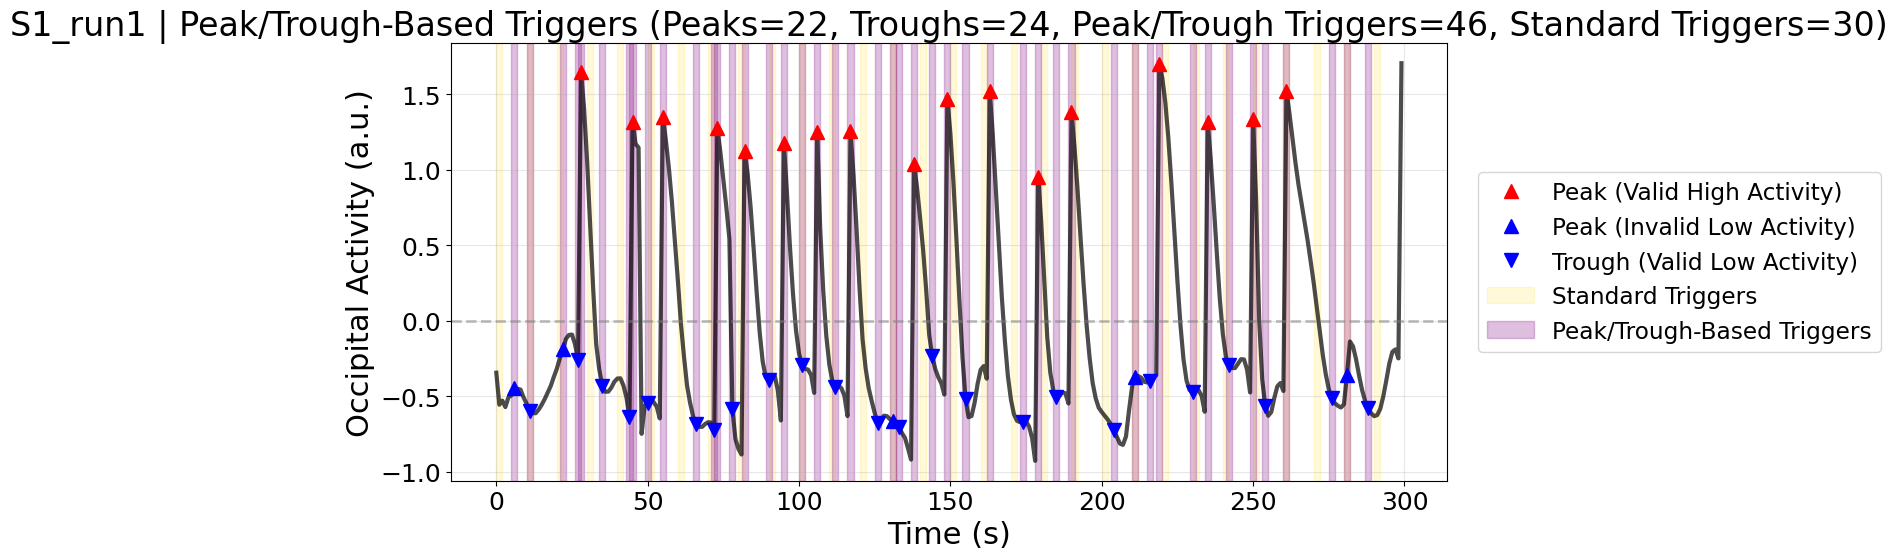

✓ S1_run1: P=22, T=24, Activity=18, PT=46, Std=30


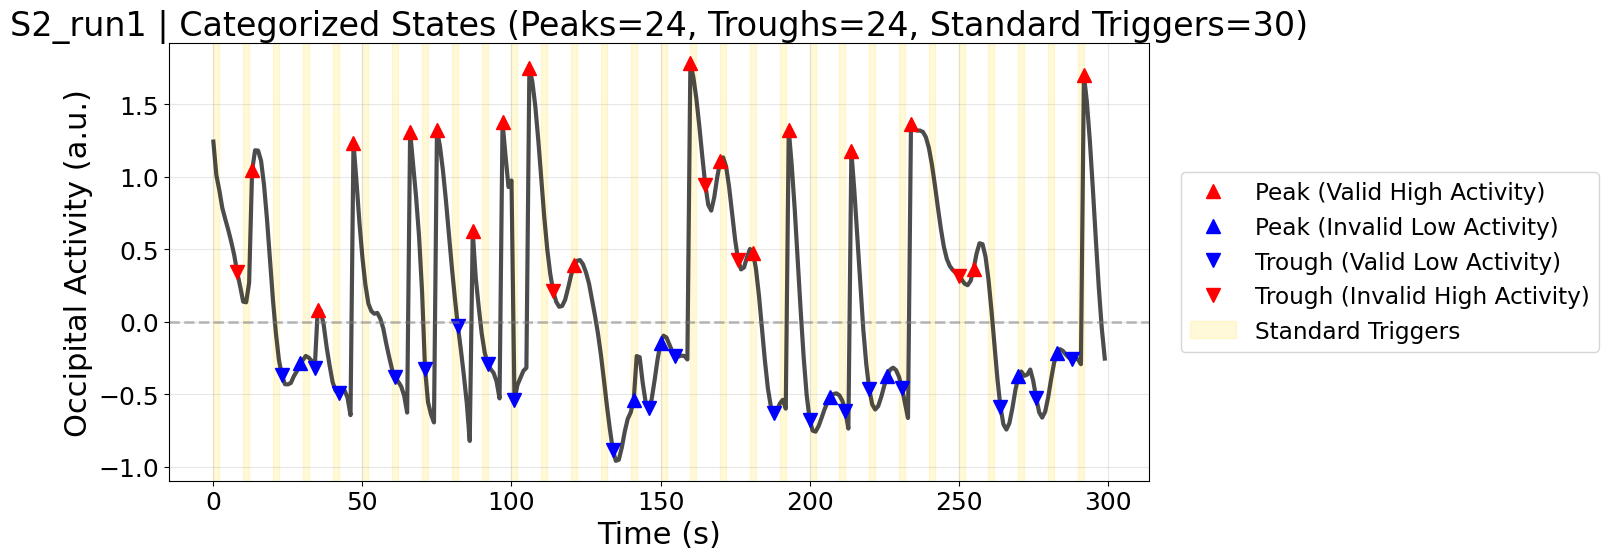

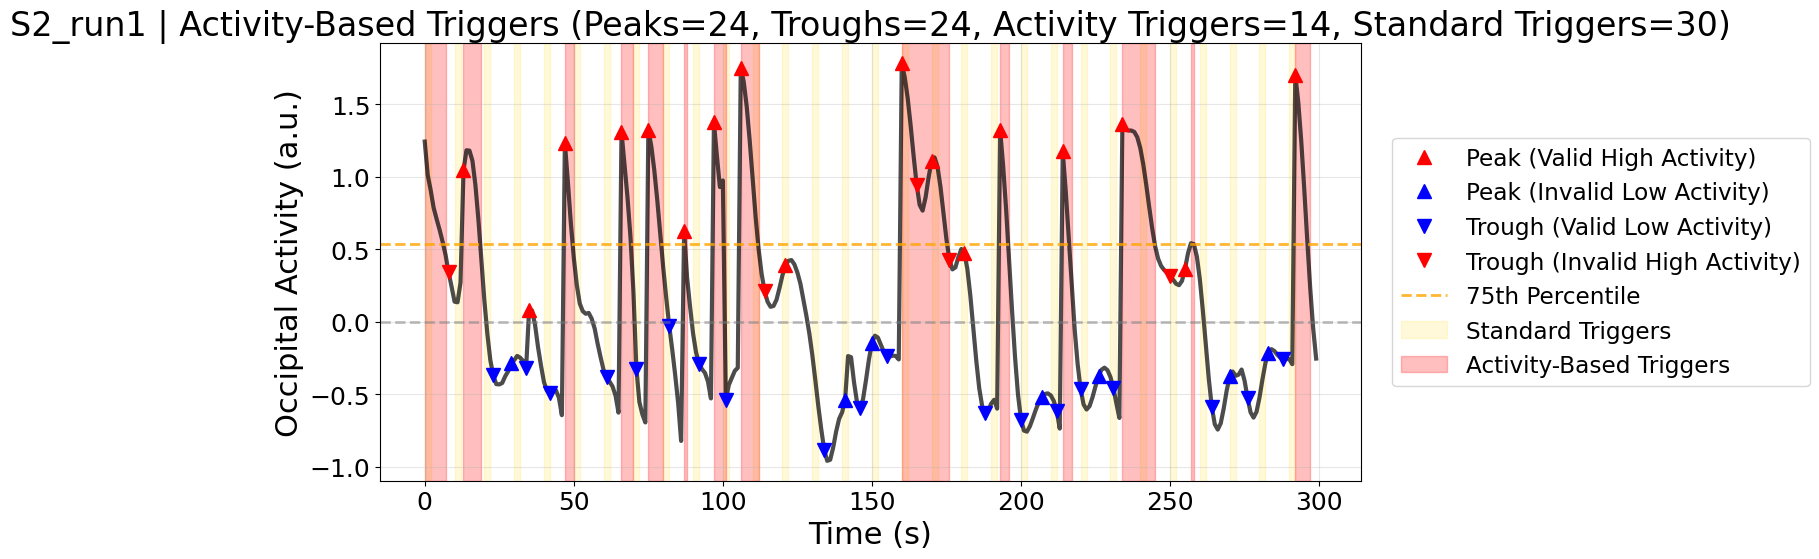

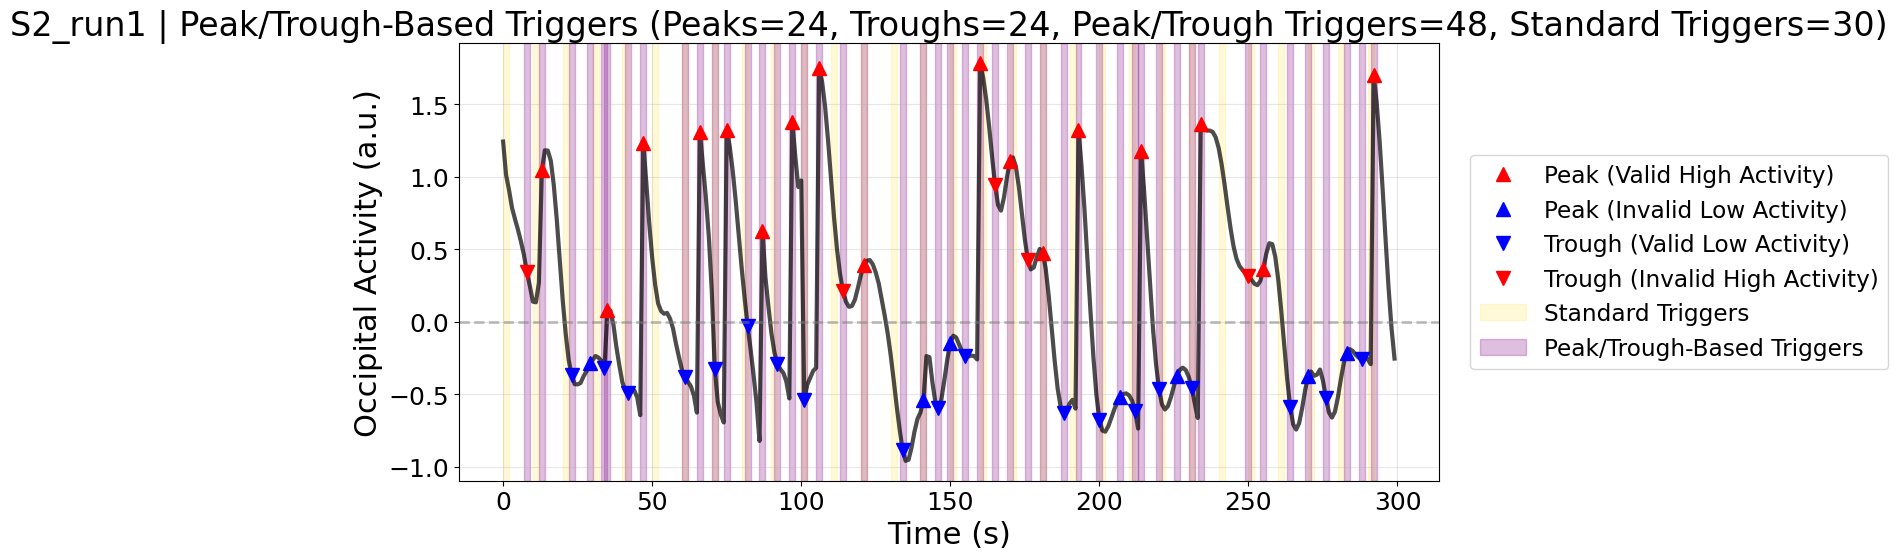

✓ S2_run1: P=24, T=24, Activity=14, PT=48, Std=30


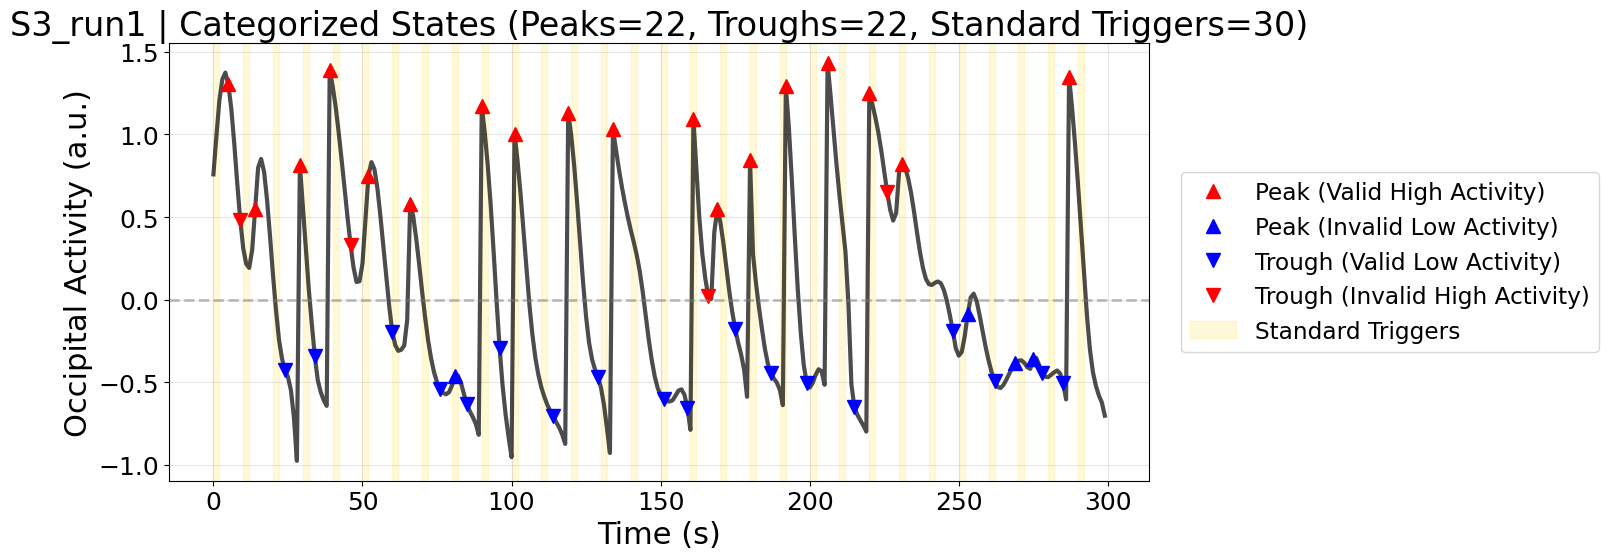

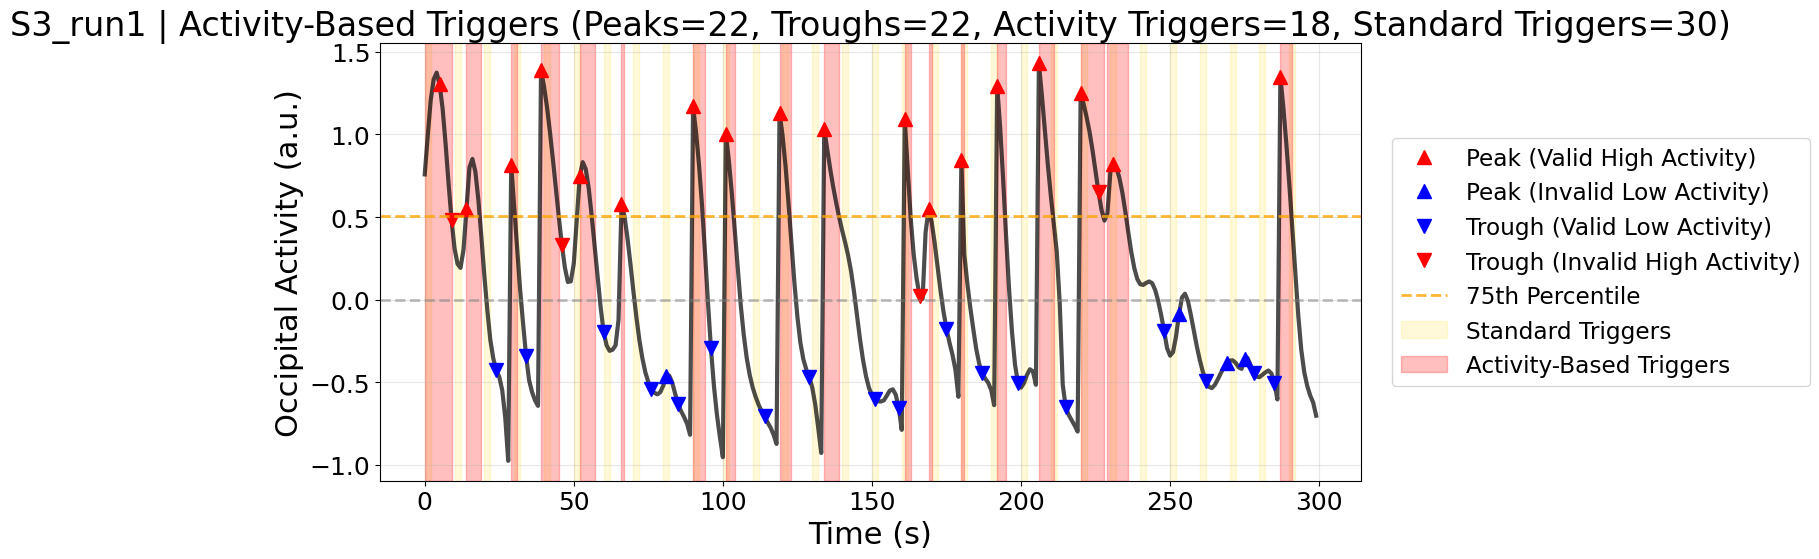

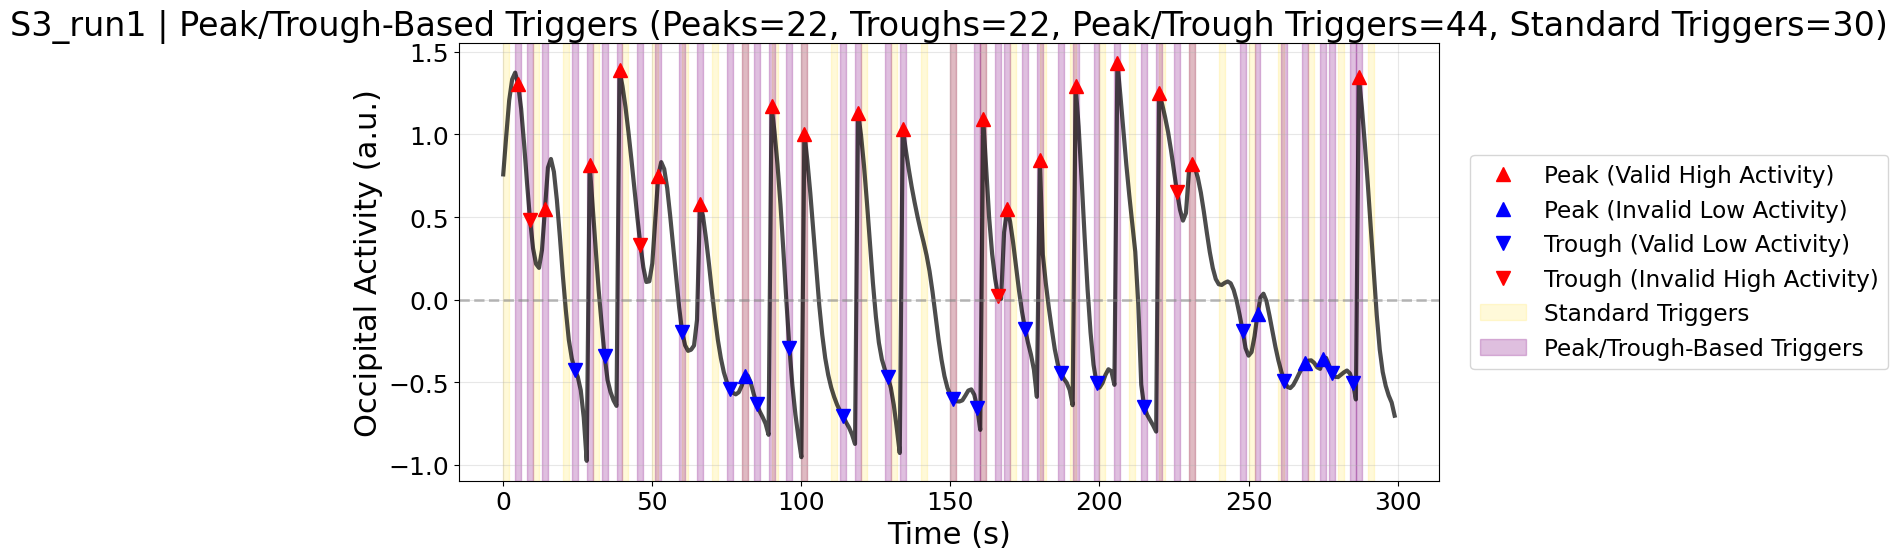

✓ S3_run1: P=22, T=22, Activity=18, PT=44, Std=30


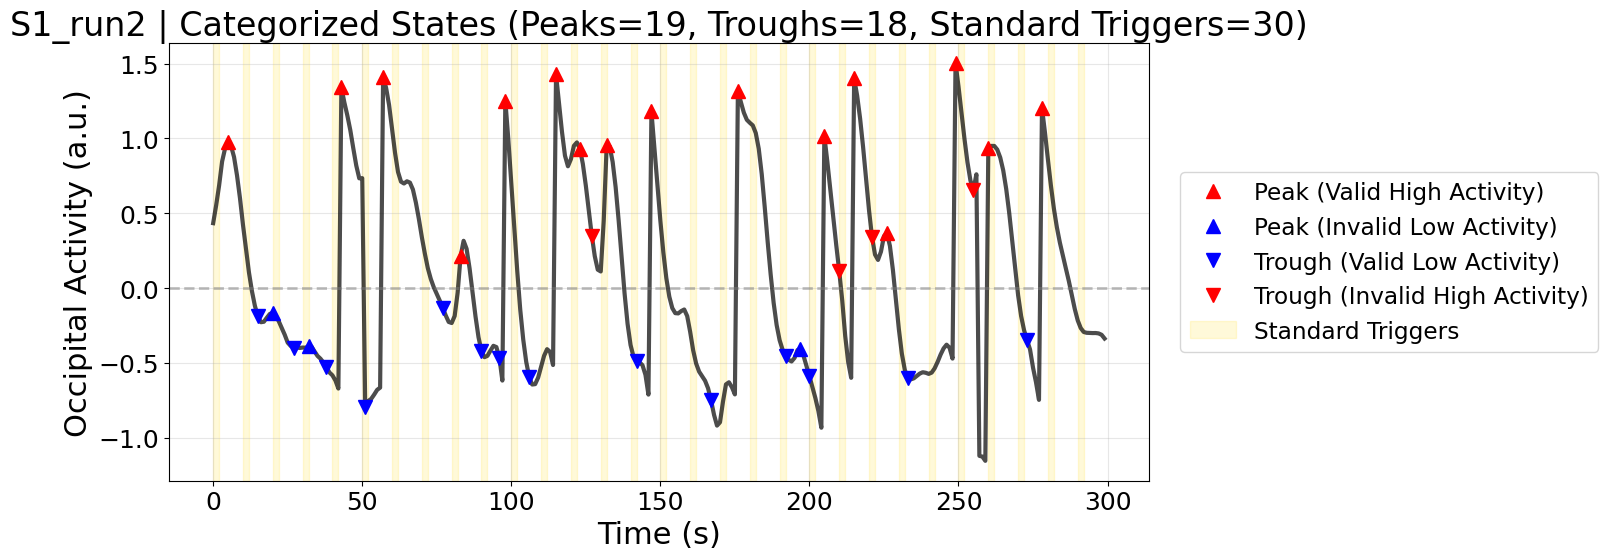

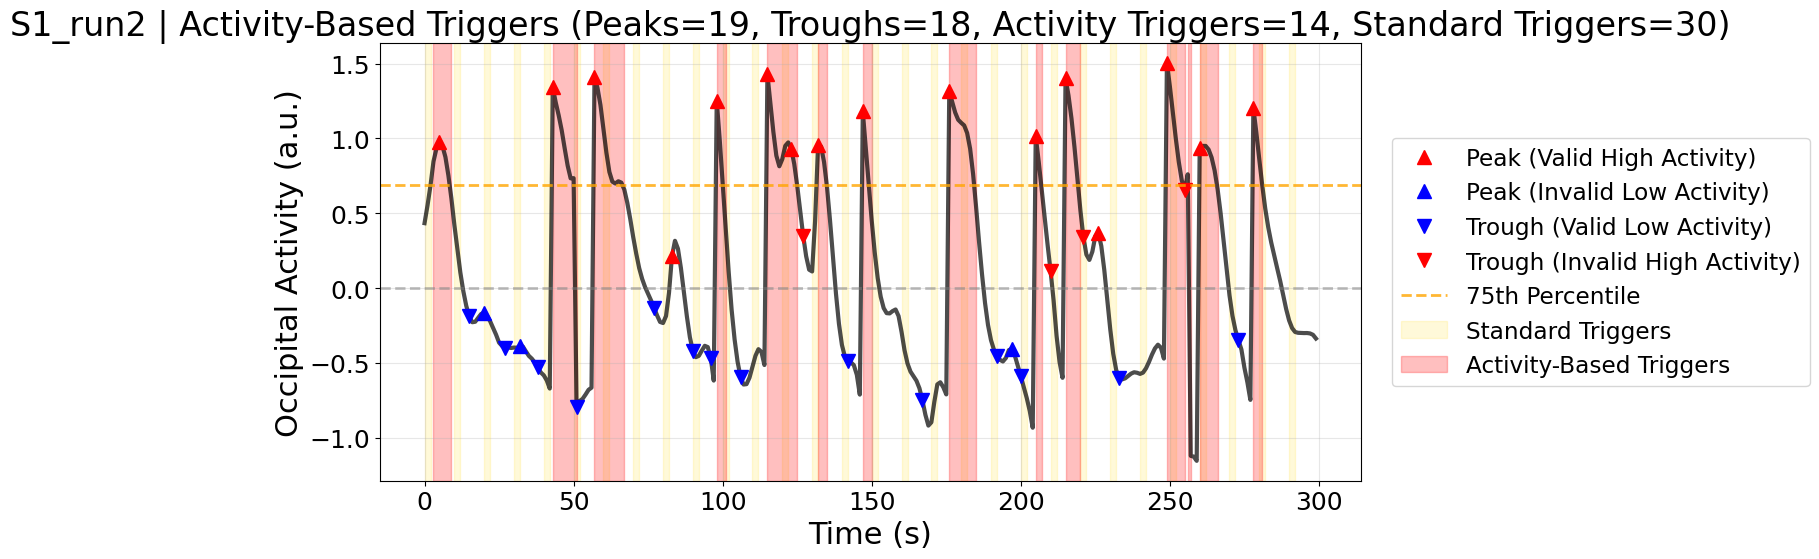

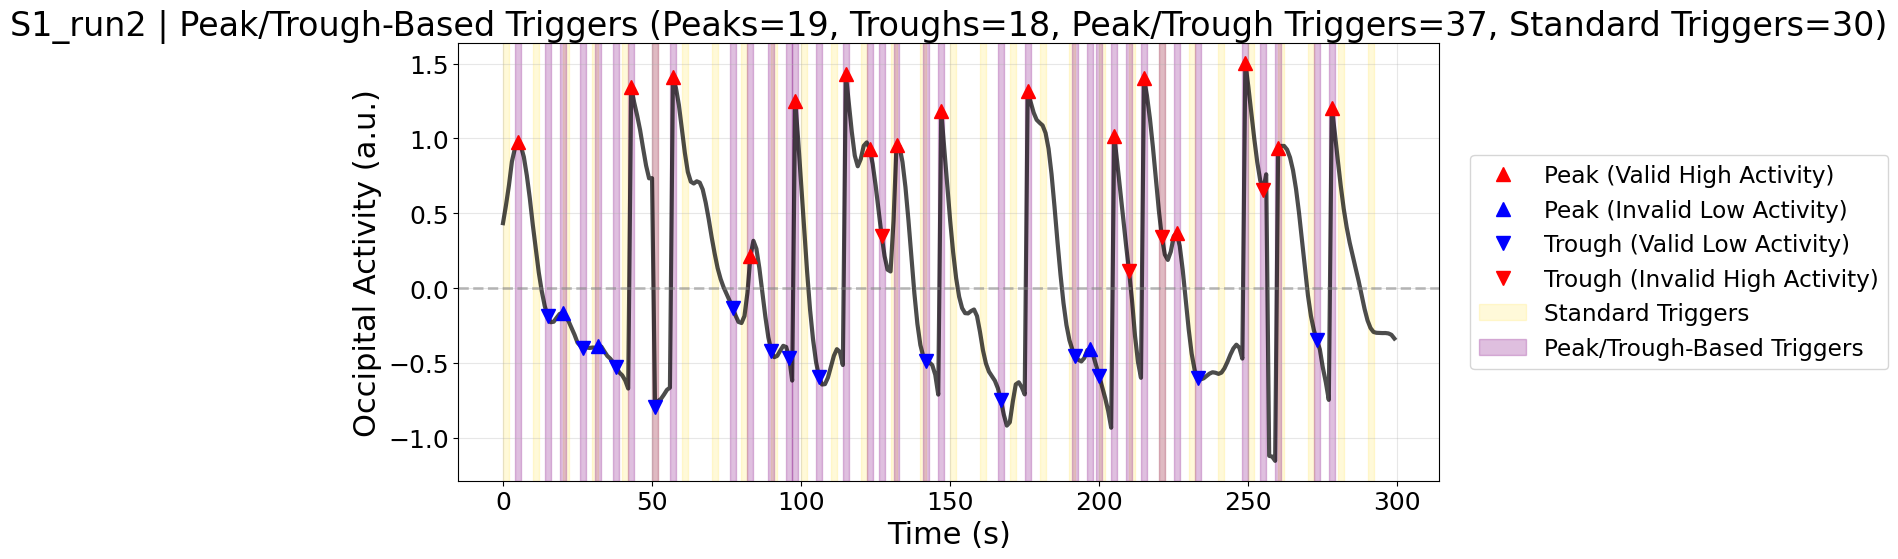

✓ S1_run2: P=19, T=18, Activity=14, PT=37, Std=30


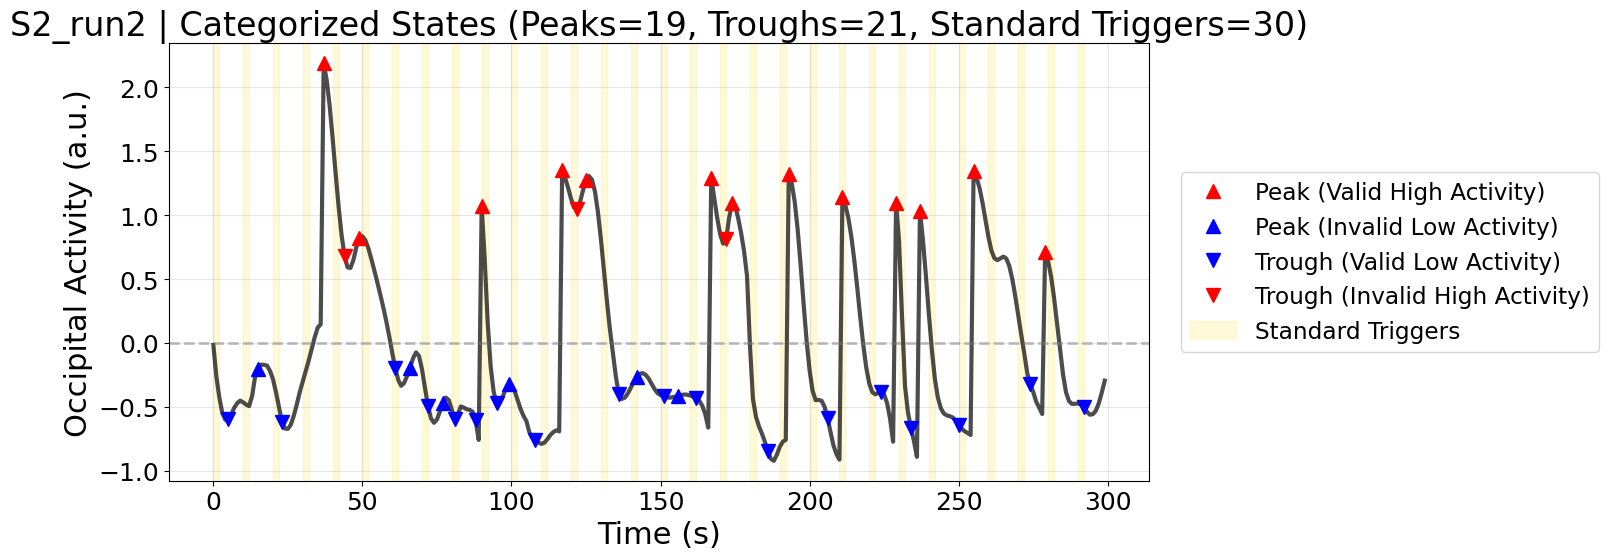

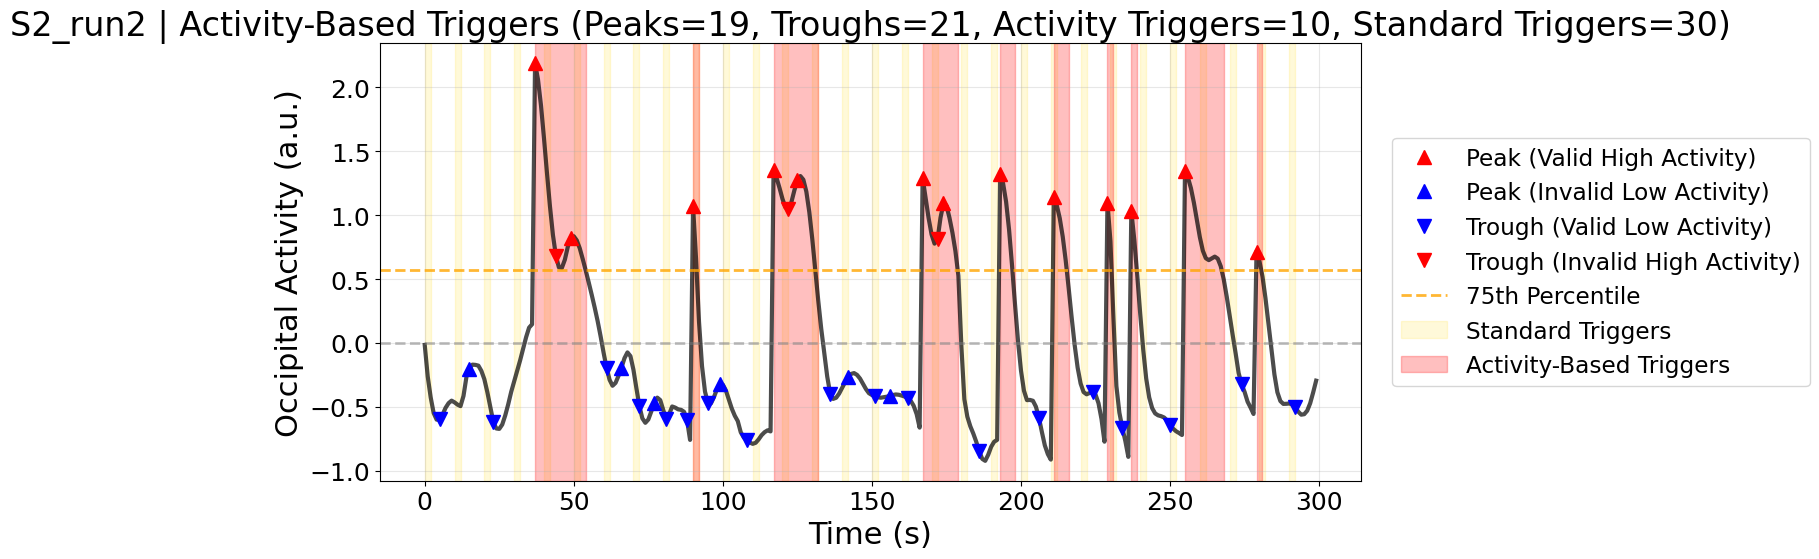

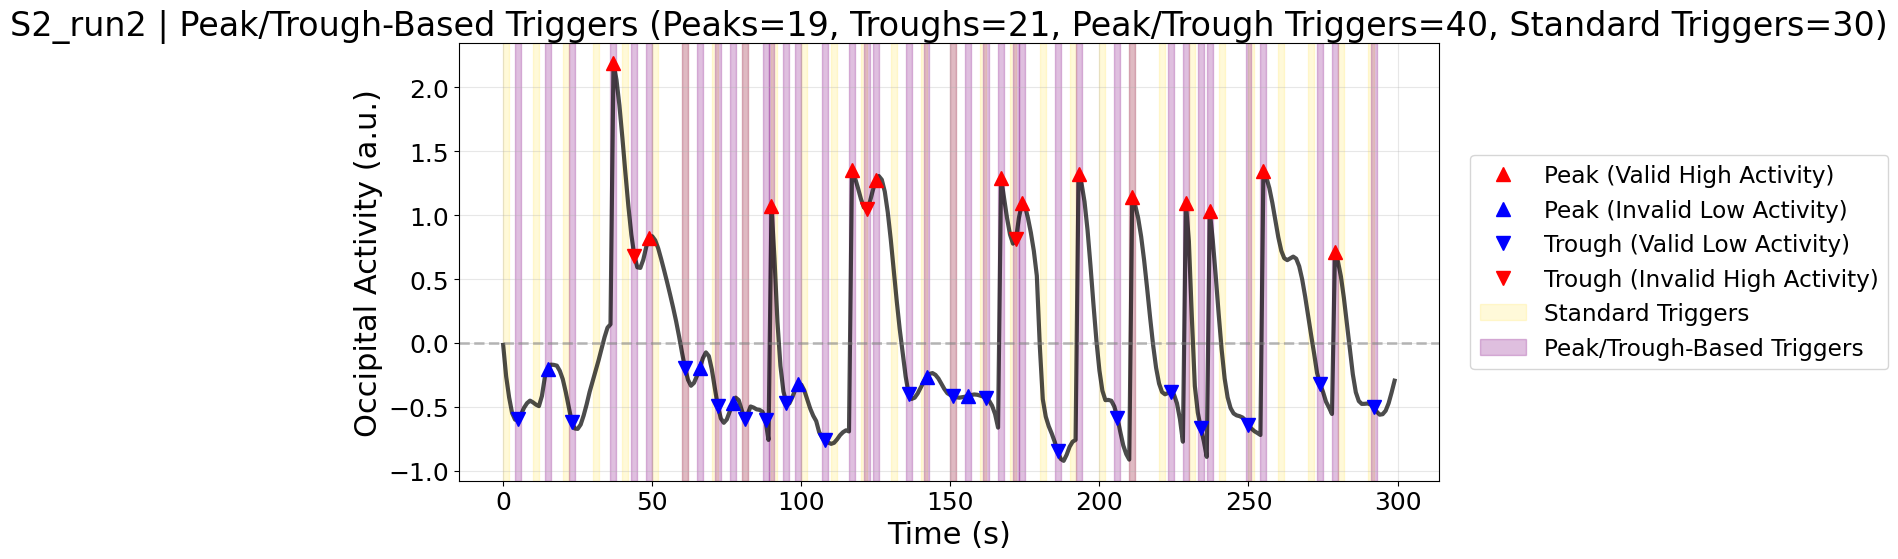

✓ S2_run2: P=19, T=21, Activity=10, PT=40, Std=30


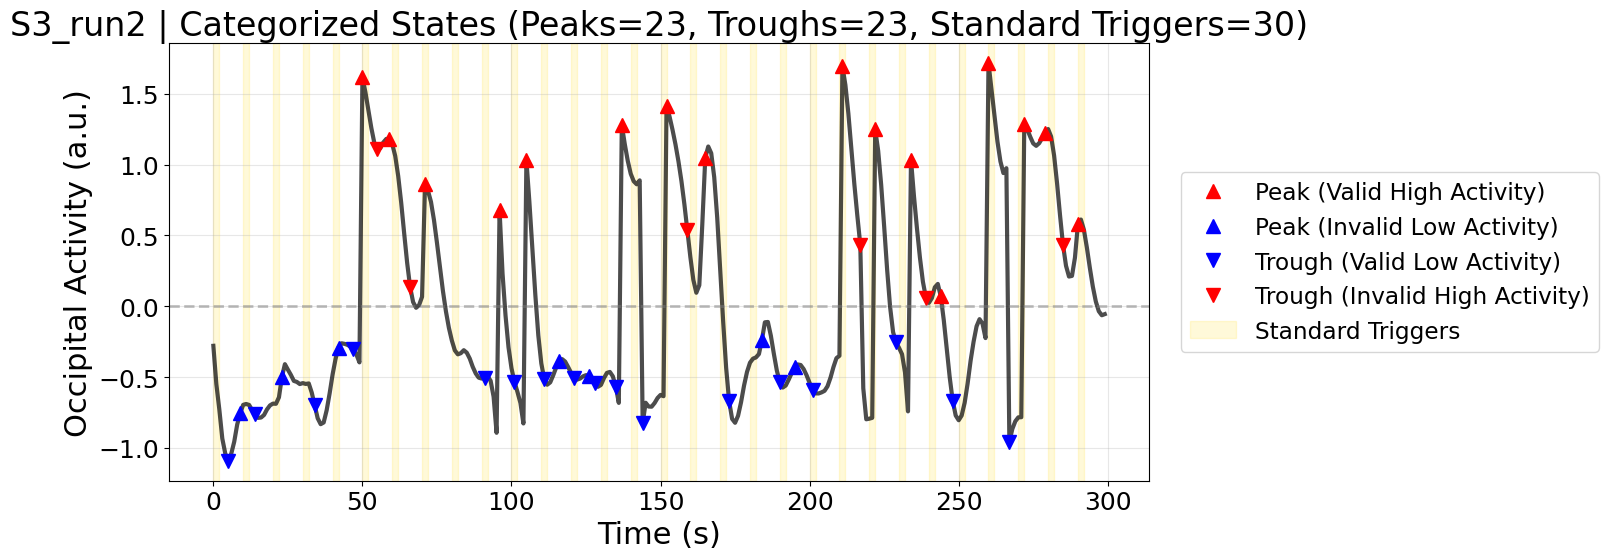

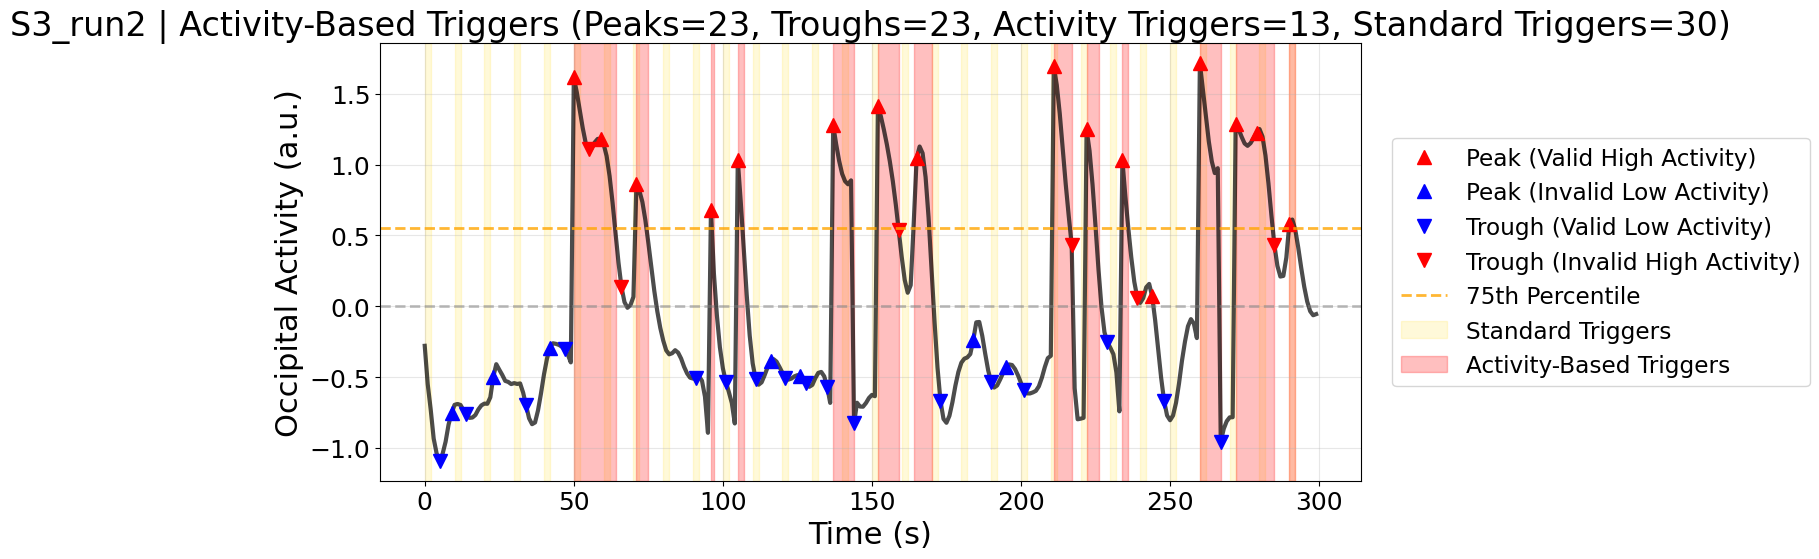

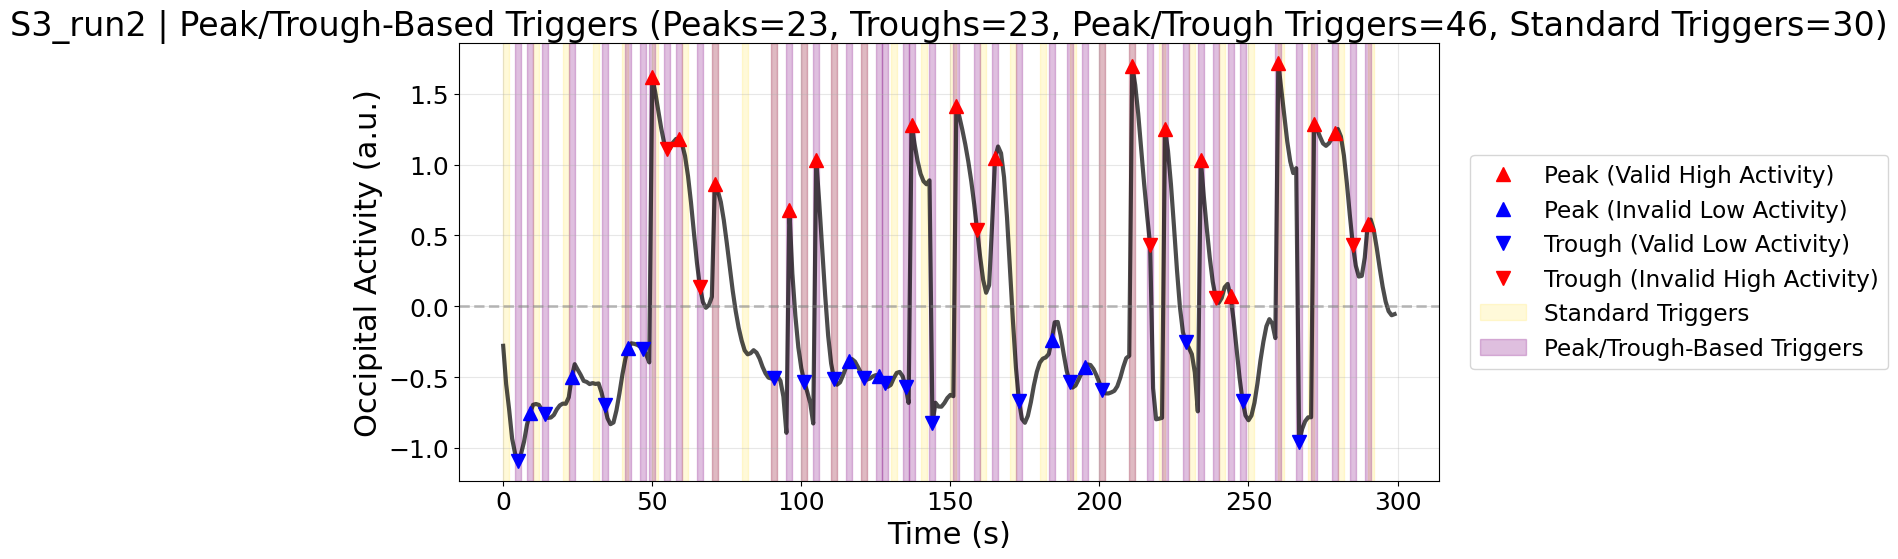

✓ S3_run2: P=23, T=23, Activity=13, PT=46, Std=30


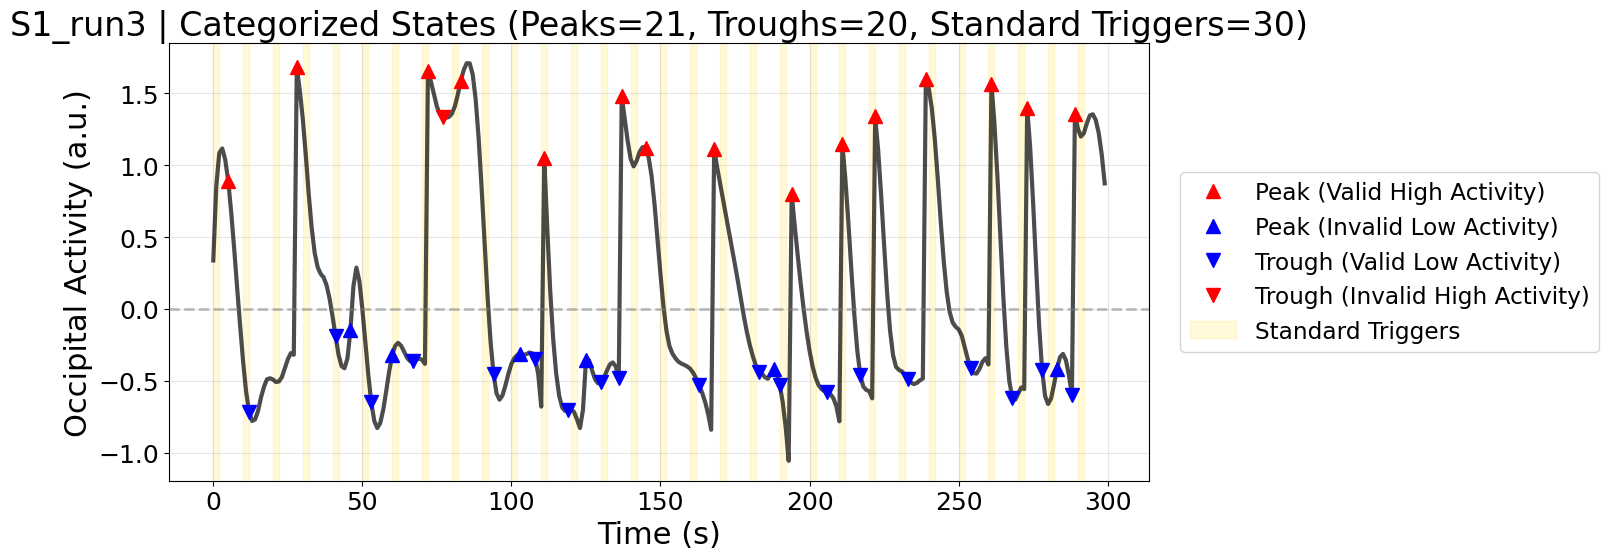

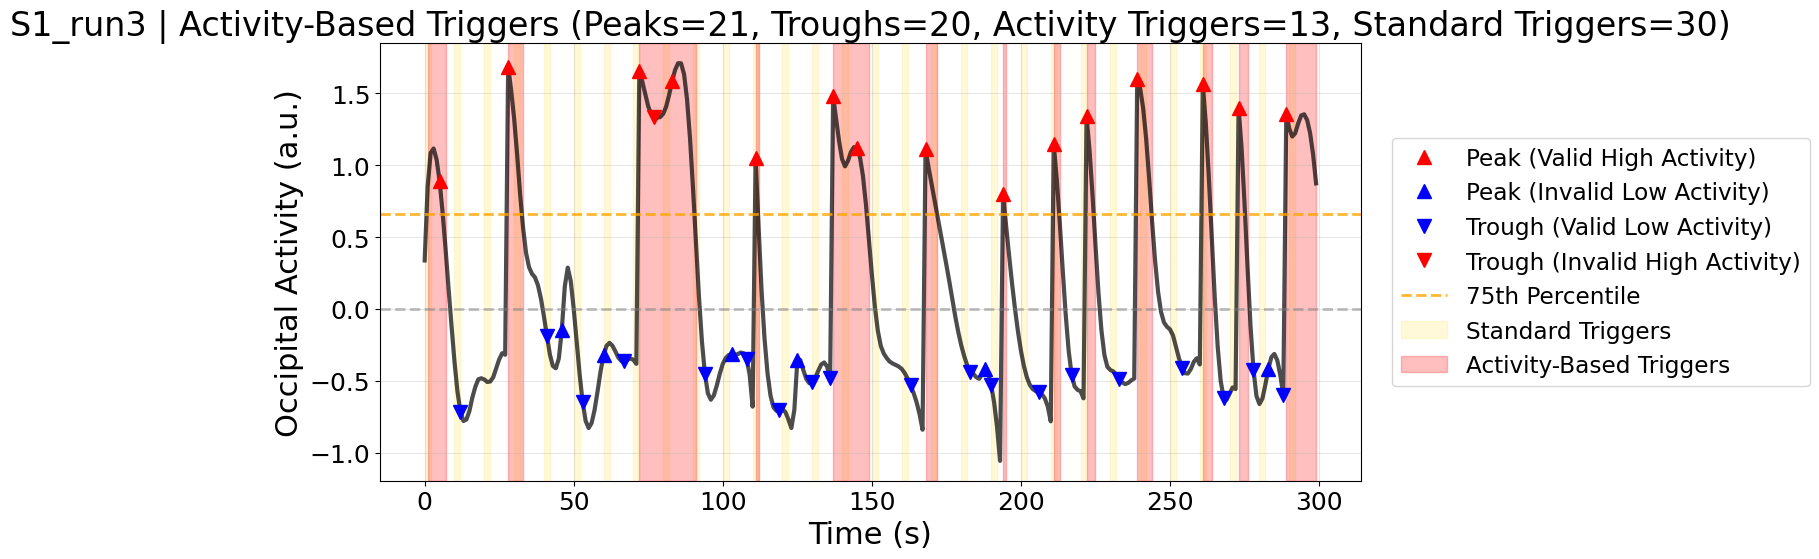

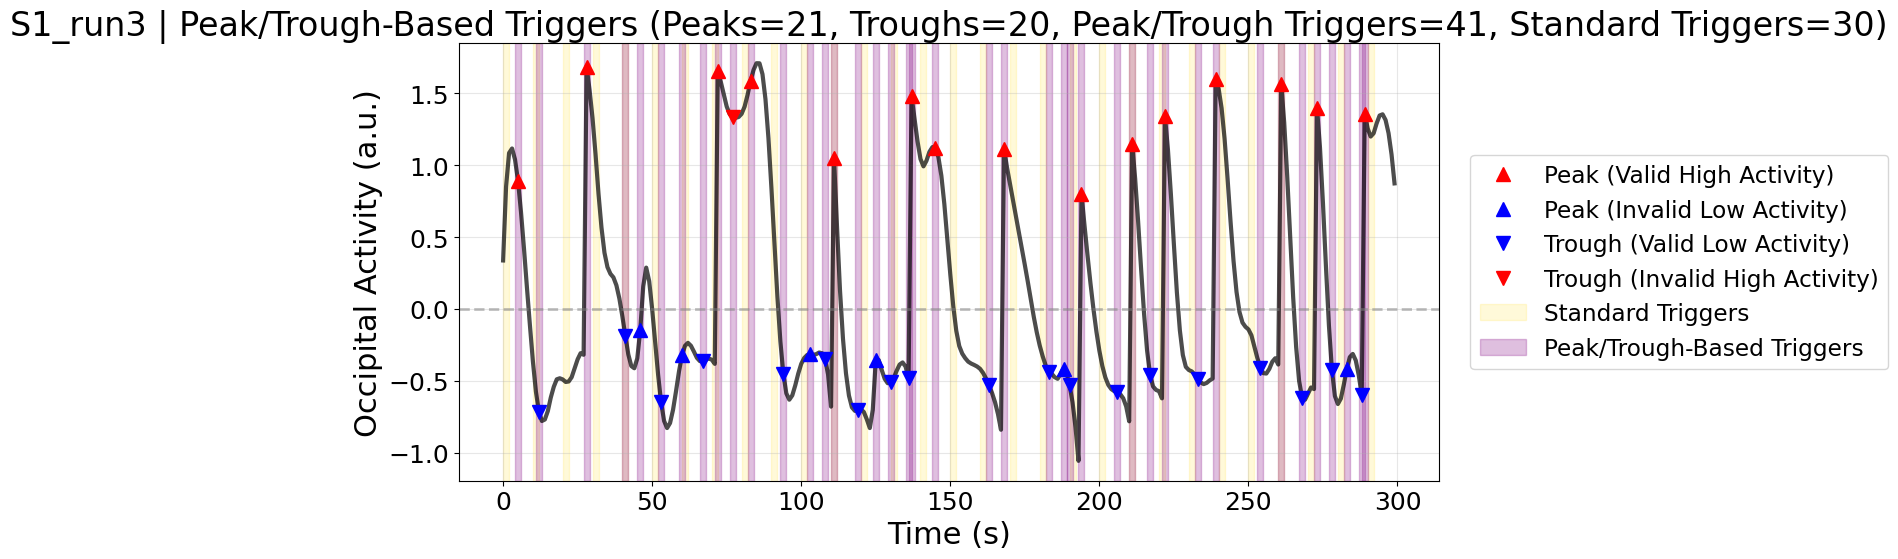

✓ S1_run3: P=21, T=20, Activity=13, PT=41, Std=30


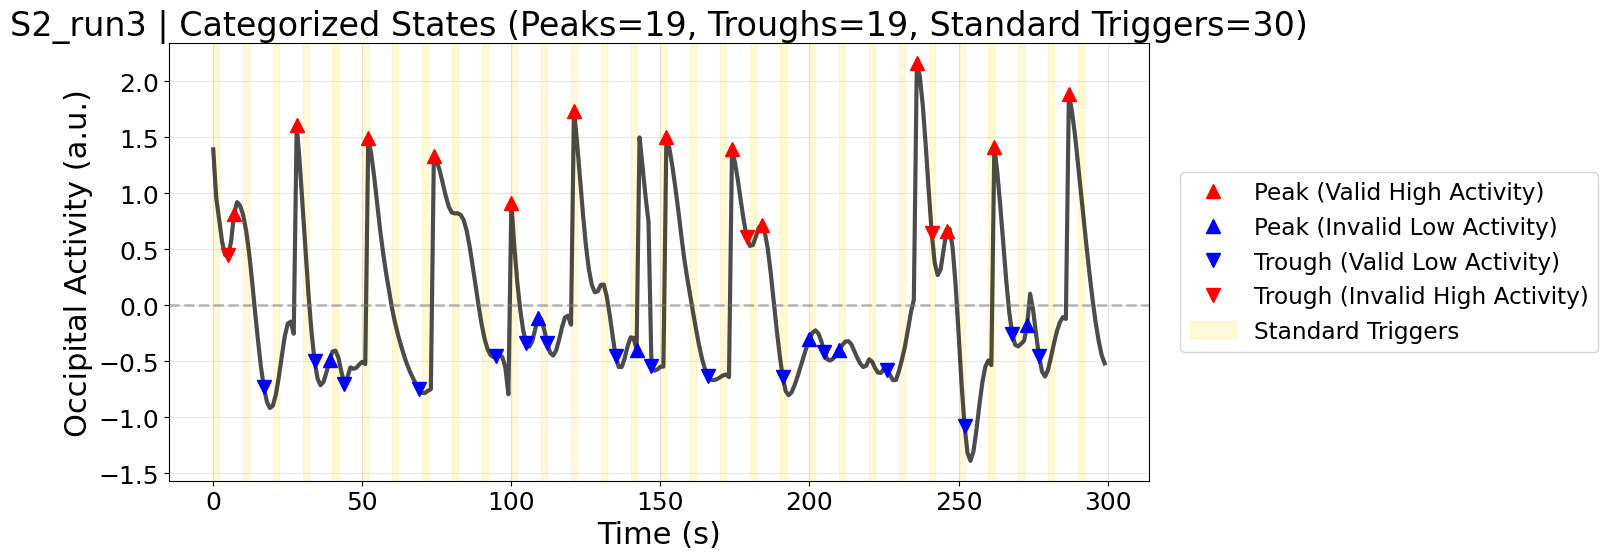

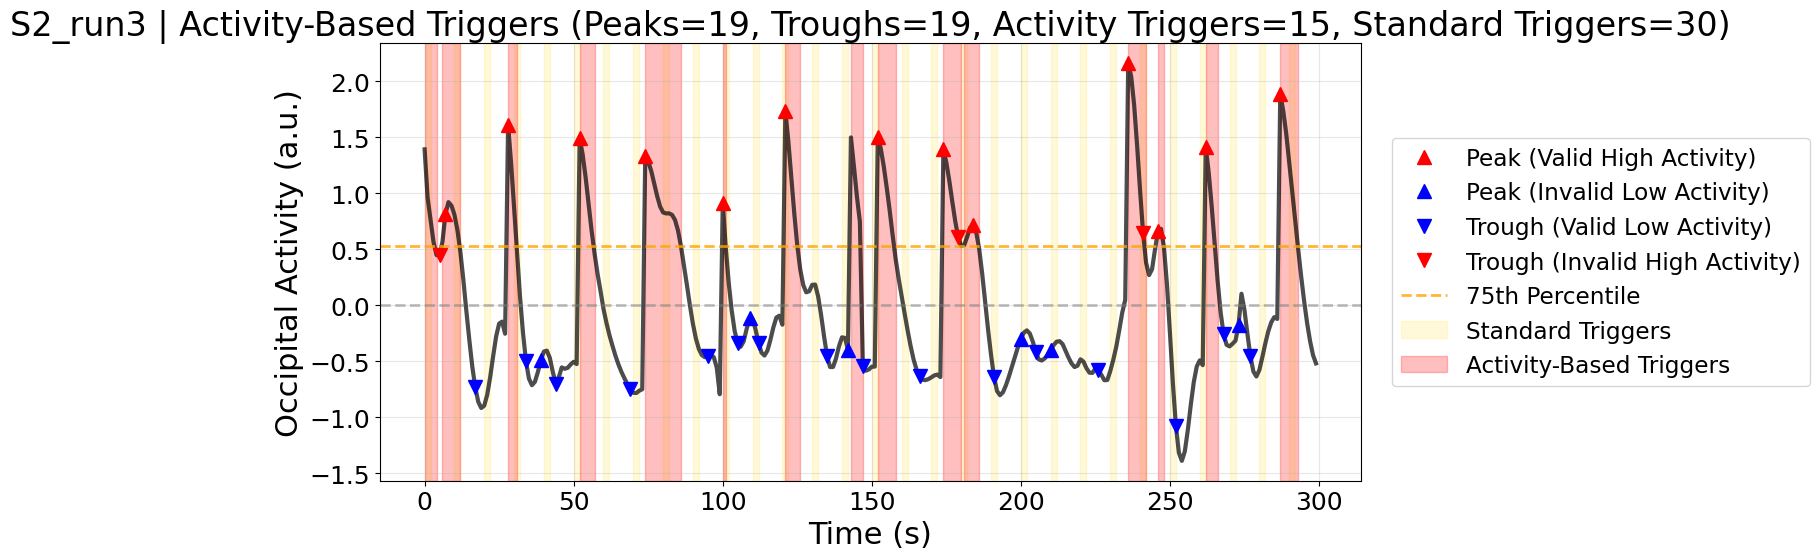

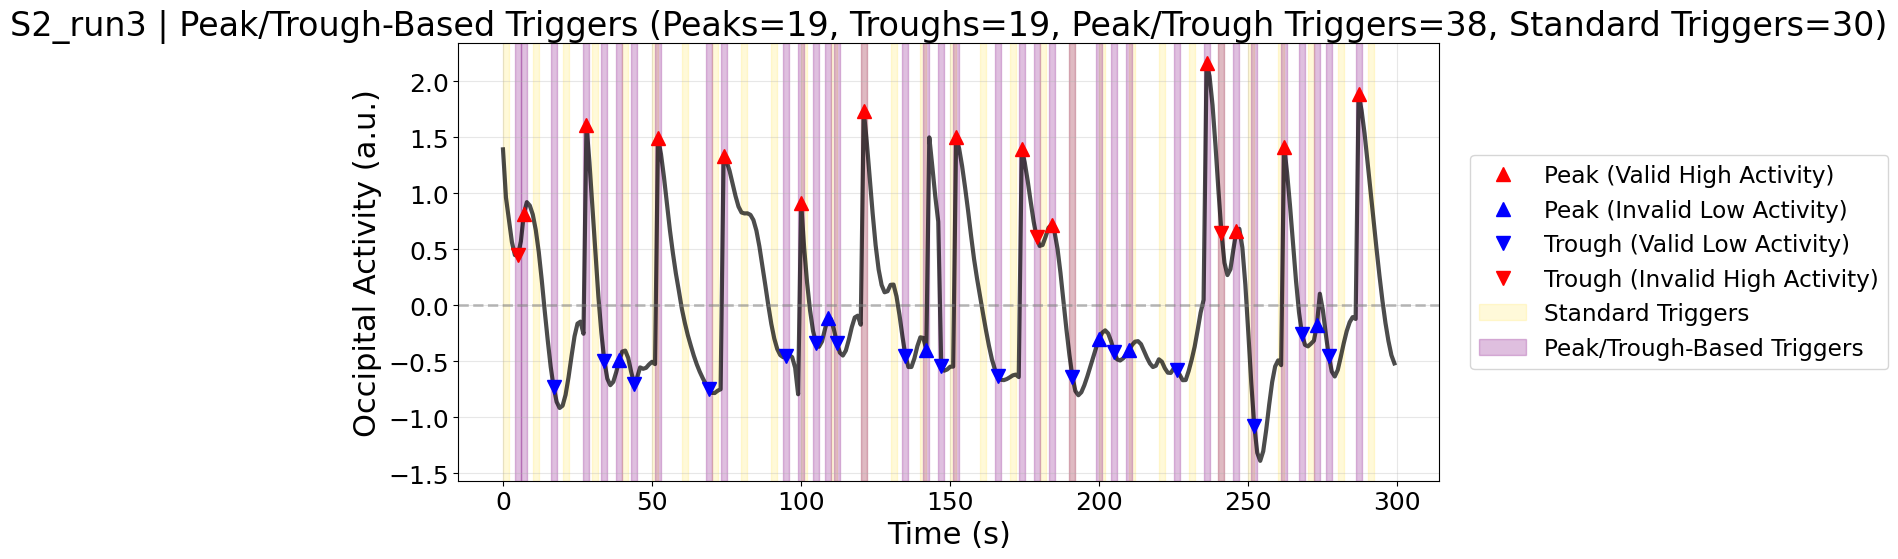

✓ S2_run3: P=19, T=19, Activity=15, PT=38, Std=30


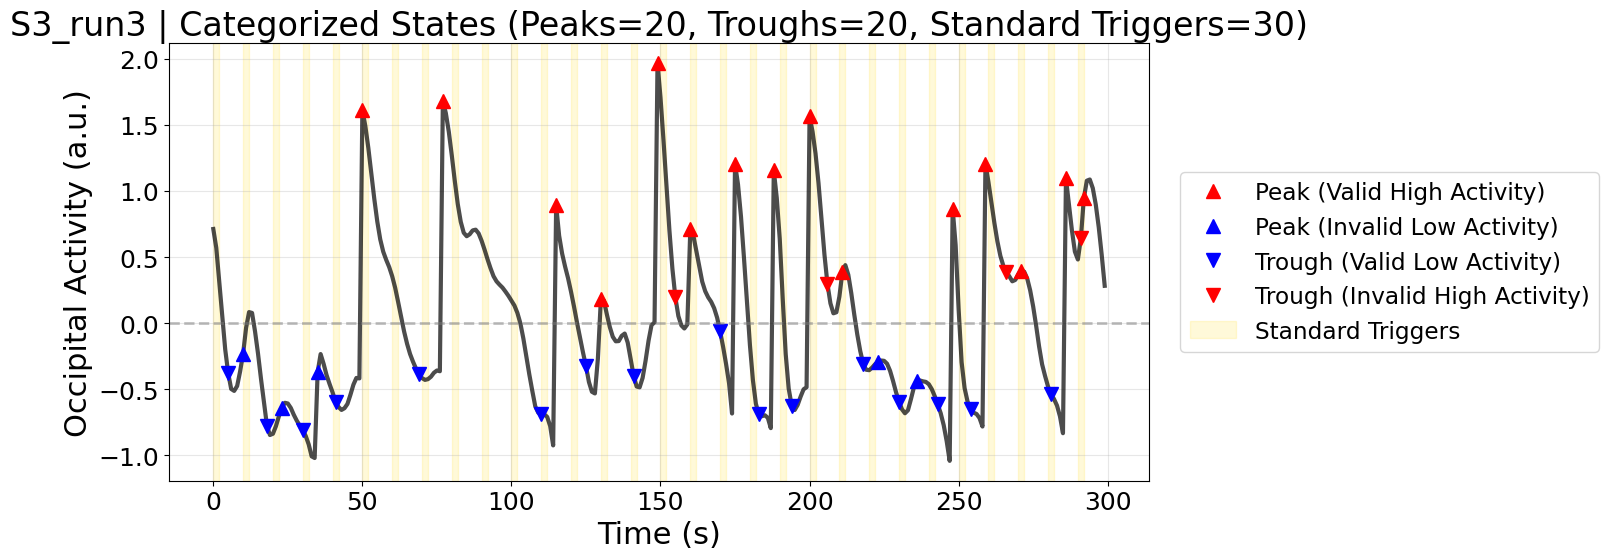

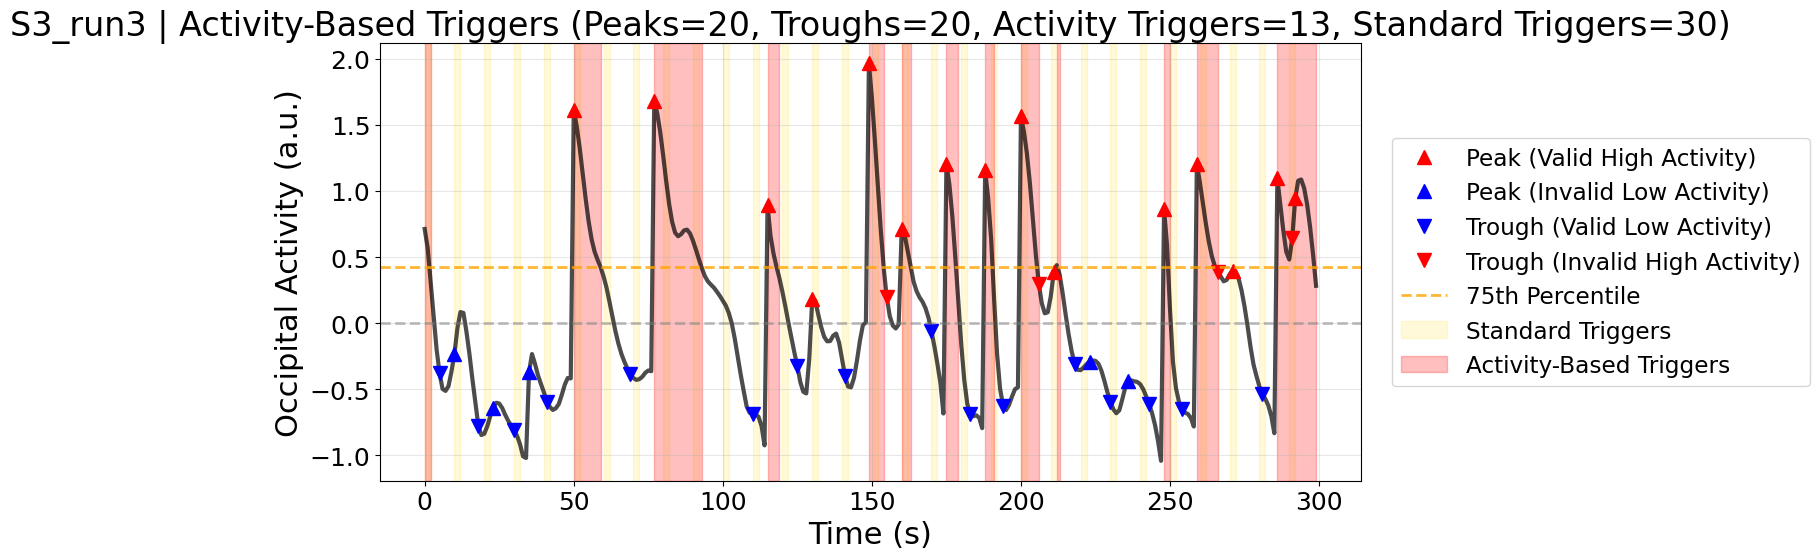

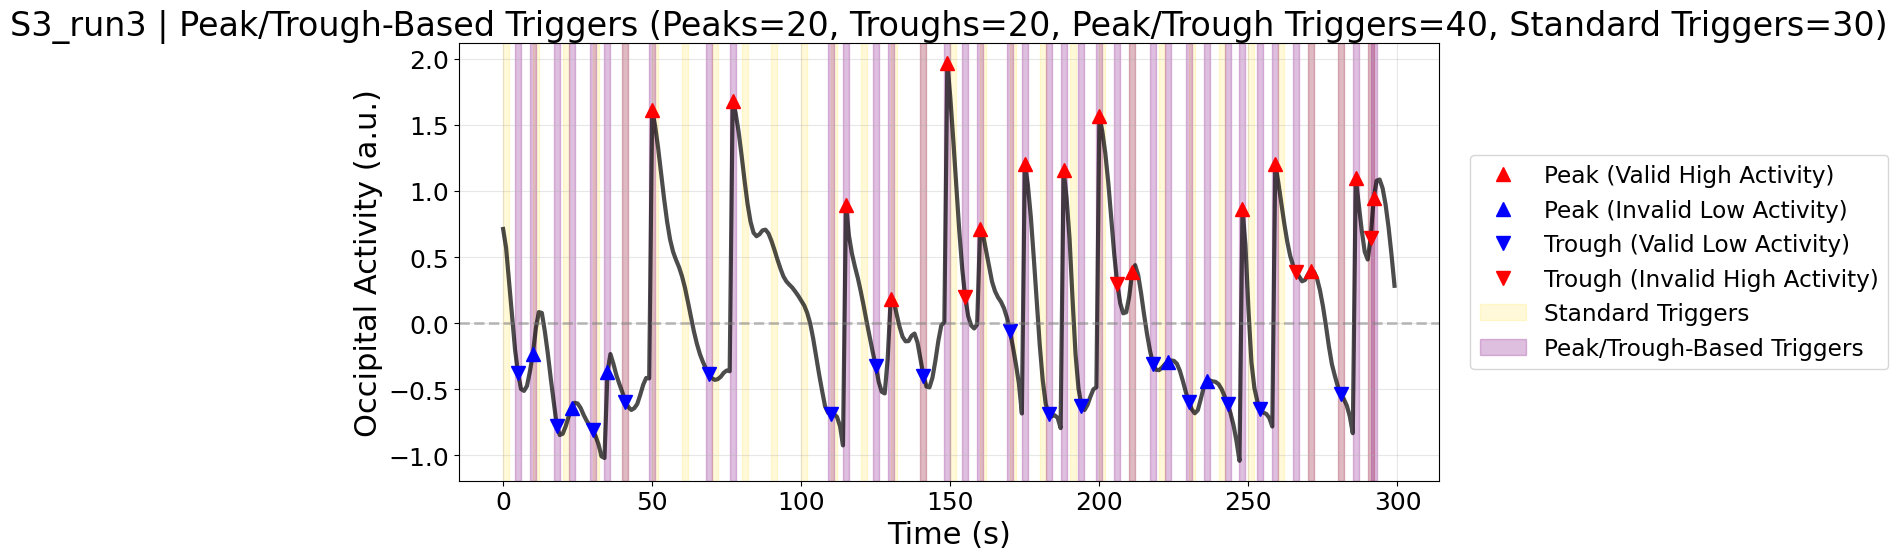

✓ S3_run3: P=20, T=20, Activity=13, PT=40, Std=30

✓✓✓ Generated 27 plots ✓✓✓


In [ ]:
results_summary = []

for idx, csv_file in enumerate(csv_files):
    session_id = f'S{(idx % 3) + 1}_run{(idx // 3) + 1}'
    subject = f'S{(idx % 3) + 1}'

    df = pd.read_csv(csv_file)
    tr = df['time_s'].iloc[1] - df['time_s'].iloc[0]

    numeric_cols = [c for c in df.columns if c != 'time_s' and df[c].dtype in [np.float64, np.float32]]
    activity = -df[numeric_cols].mean(axis=1).values

    max_idx = int(300 / tr) if len(df) > 300/tr else len(df)
    time_subset = df['time_s'].iloc[:max_idx].values
    activity_subset = activity[:max_idx]

    distance = int(MIN_PEAK_DISTANCE_SEC / tr)
    peaks = find_peaks_numpy(activity_subset, distance)
    troughs = find_peaks_numpy(-activity_subset, distance)

    peaks_high = peaks[activity_subset[peaks] > 0]
    peaks_low = peaks[activity_subset[peaks] <= 0]
    troughs_low = troughs[activity_subset[troughs] < 0]
    troughs_high = troughs[activity_subset[troughs] >= 0]

    threshold = np.percentile(activity_subset, ACTIVITY_THRESHOLD_PERCENTILE)
    high_activity = activity_subset > threshold
    diff = np.diff(np.concatenate(([0], high_activity.astype(int), [0])))
    threshold_starts = np.where(diff == 1)[0]
    threshold_ends = np.where(diff == -1)[0]

    if len(threshold_starts) == 0 and len(peaks_high) > 0:
        duration_samples = int(2 / tr)
        trigger_starts = []
        trigger_ends = []
        for peak_idx in peaks_high:
            start = max(0, peak_idx - duration_samples // 2)
            end = min(len(activity_subset), peak_idx + duration_samples // 2)
            trigger_starts.append(start)
            trigger_ends.append(end)
        trigger_starts = np.array(trigger_starts)
        trigger_ends = np.array(trigger_ends)
        n_activity_triggers = len(trigger_starts)
        trigger_method = 'peak-based'
    elif len(threshold_starts) > 0:
        trigger_starts = threshold_starts
        trigger_ends = threshold_ends
        n_activity_triggers = len(trigger_starts)
        trigger_method = 'threshold-based'
    else:
        max_idx_activity = np.argmax(activity_subset)
        duration_samples = int(10 / tr)
        start = max(0, max_idx_activity - duration_samples // 2)
        end = min(len(activity_subset), max_idx_activity + duration_samples // 2)
        trigger_starts = np.array([start])
        trigger_ends = np.array([end])
        n_activity_triggers = 1
        trigger_method = 'max-activity'

    # Generate peak/trough-based triggers (2-sec windows centered on peaks and troughs)
    duration_samples = int(2 / tr)
    pt_trigger_starts = []
    pt_trigger_ends = []
    for idx_p in peaks:
        start = max(0, idx_p - duration_samples // 2)
        end = min(len(activity_subset), idx_p + duration_samples // 2)
        pt_trigger_starts.append(start)
        pt_trigger_ends.append(end)
    for idx_t in troughs:
        start = max(0, idx_t - duration_samples // 2)
        end = min(len(activity_subset), idx_t + duration_samples // 2)
        pt_trigger_starts.append(start)
        pt_trigger_ends.append(end)
    pt_trigger_starts = np.array(sorted(pt_trigger_starts))
    pt_trigger_ends = np.array(sorted(pt_trigger_ends))
    n_pt_triggers = len(pt_trigger_starts)

    burst_starts_time = []
    burst_ends_time = []
    t = 0
    while t < time_subset[-1]:
        burst_starts_time.append(t)
        burst_ends_time.append(min(t + STANDARD_BURST_DURATION_SEC, time_subset[-1]))
        t += STANDARD_BURST_INTERVAL_SEC
    n_standard = len(burst_starts_time)

    results_summary.append({
        'Session': session_id,
        'Subject': subject,
        'Peaks': len(peaks),
        'Troughs': len(troughs),
        'Activity Triggers': n_activity_triggers,
        'Peak/Trough Triggers': n_pt_triggers,
        'Standard Triggers': n_standard
    })

    # PLOT 1: Categorized States
    fig1, ax1 = plt.subplots(figsize=(16, 6))
    ax1.plot(time_subset, activity_subset, color='black', alpha=0.7)
    plot_categorized_markers(ax1, time_subset, activity_subset, peaks_high, peaks_low, troughs_low, troughs_high)
    ax1.axhline(0, color='grey', linestyle='--', alpha=0.5, lw=2)
    for i, (start, end) in enumerate(zip(burst_starts_time, burst_ends_time)):
        ax1.axvspan(start, end, alpha=0.15, color='gold', label='Standard Triggers' if i == 0 else '')
    ax1.set_title(f'{session_id} | Categorized States (Peaks={len(peaks)}, Troughs={len(troughs)}, Standard Triggers={n_standard})')
    ax1.set_xlabel('Time (s)')
    ax1.set_ylabel('Occipital Activity (a.u.)')
    ax1.legend(loc='center left', bbox_to_anchor=(1.02, 0.5), fontsize='small')
    ax1.grid(True, alpha=0.3)
    plt.tight_layout()
    plt.show()
    plt.close()

    # PLOT 2: Activity-Based Triggers
    fig2, ax2 = plt.subplots(figsize=(16, 6))
    ax2.plot(time_subset, activity_subset, color='black', alpha=0.7)
    plot_categorized_markers(ax2, time_subset, activity_subset, peaks_high, peaks_low, troughs_low, troughs_high)
    ax2.axhline(0, color='grey', linestyle='--', alpha=0.5, lw=2)
    ax2.axhline(y=threshold, color='orange', linestyle='--', linewidth=2, alpha=0.8, label=f'{ACTIVITY_THRESHOLD_PERCENTILE}th Percentile')
    for i, (start, end) in enumerate(zip(burst_starts_time, burst_ends_time)):
        ax2.axvspan(start, end, alpha=0.15, color='gold', label='Standard Triggers' if i == 0 else '')
    for i, (start, end) in enumerate(zip(trigger_starts, trigger_ends)):
        start_time = time_subset[start]
        end_time = time_subset[end] if end < len(time_subset) else time_subset[-1]
        ax2.axvspan(start_time, end_time, alpha=0.25, color='red', label='Activity-Based Triggers' if i == 0 else '')
    ax2.set_title(f'{session_id} | Activity-Based Triggers (Peaks={len(peaks)}, Troughs={len(troughs)}, Activity Triggers={n_activity_triggers}, Standard Triggers={n_standard})')
    ax2.set_xlabel('Time (s)')
    ax2.set_ylabel('Occipital Activity (a.u.)')
    ax2.legend(loc='center left', bbox_to_anchor=(1.02, 0.5), fontsize='small')
    ax2.grid(True, alpha=0.3)
    plt.tight_layout()
    plt.show()
    plt.close()

    # PLOT 3: Peak/Trough-Based Triggers
    fig3, ax3 = plt.subplots(figsize=(16, 6))
    ax3.plot(time_subset, activity_subset, color='black', alpha=0.7)
    plot_categorized_markers(ax3, time_subset, activity_subset, peaks_high, peaks_low, troughs_low, troughs_high)
    ax3.axhline(0, color='grey', linestyle='--', alpha=0.5, lw=2)
    for i, (start, end) in enumerate(zip(burst_starts_time, burst_ends_time)):
        ax3.axvspan(start, end, alpha=0.15, color='gold', label='Standard Triggers' if i == 0 else '')
    for i, (start, end) in enumerate(zip(pt_trigger_starts, pt_trigger_ends)):
        start_time = time_subset[start]
        end_time = time_subset[end] if end < len(time_subset) else time_subset[-1]
        ax3.axvspan(start_time, end_time, alpha=0.25, color='purple', label='Peak/Trough-Based Triggers' if i == 0 else '')
    ax3.set_title(f'{session_id} | Peak/Trough-Based Triggers (Peaks={len(peaks)}, Troughs={len(troughs)}, Peak/Trough Triggers={n_pt_triggers}, Standard Triggers={n_standard})')
    ax3.set_xlabel('Time (s)')
    ax3.set_ylabel('Occipital Activity (a.u.)')
    ax3.legend(loc='center left', bbox_to_anchor=(1.02, 0.5), fontsize='small')
    ax3.grid(True, alpha=0.3)
    plt.tight_layout()
    plt.show()
    plt.close()

    print(f'✓ {session_id}: P={len(peaks)}, T={len(troughs)}, Activity={n_activity_triggers}, PT={n_pt_triggers}, Std={n_standard}')

print(f'\n✓✓✓ Generated {len(csv_files)*3} plots ✓✓✓')

In [ ]:
summary_df = pd.DataFrame(results_summary)
print('\n' + '='*180)
print('OCCIPITAL fNIRS ACTIVITY-BASED iTBS TRIGGERING ANALYSIS')
print('='*180)
print(summary_df.to_string(index=False))
print('='*180)
print(f'\nTotal Sessions: {len(summary_df)}')
print(f'Total Peaks: {summary_df["Peaks"].sum():.0f}')
print(f'Total Troughs: {summary_df["Troughs"].sum():.0f}')
print(f'Total Activity-Based Triggers: {summary_df["Activity Triggers"].sum():.0f}')
print(f'Total Peak/Trough-Based Triggers: {summary_df["Peak/Trough Triggers"].sum():.0f}')
print(f'Total Standard Triggers: {summary_df["Standard Triggers"].sum():.0f}')


OCCIPITAL fNIRS ACTIVITY-BASED iTBS TRIGGERING ANALYSIS
Session Subject  Peaks  Troughs  Activity Triggers  Peak/Trough Triggers  Standard Triggers
S1_run1      S1     22       24                 18                    46                 30
S2_run1      S2     24       24                 14                    48                 30
S3_run1      S3     22       22                 18                    44                 30
S1_run2      S1     19       18                 14                    37                 30
S2_run2      S2     19       21                 10                    40                 30
S3_run2      S3     23       23                 13                    46                 30
S1_run3      S1     21       20                 13                    41                 30
S2_run3      S2     19       19                 15                    38                 30
S3_run3      S3     20       20                 13                    40                 30

Total Sessions: 9
Tota

## Trigger Strategies Summary

**Plot 1 - Categorized States:** Black line with markers + standard 2s iTBS triggers every 10s (gold)  
**Plot 2 - Activity-Based:** Plot 1 + threshold-based triggers (red) at >75th percentile activity  
**Plot 3 - Peak/Trough-Based:** Plot 1 + 2-second windows centered on ALL detected peaks AND troughs (purple)  

Each plot title shows: Peaks, Troughs, Activity Triggers (or Peak/Trough Triggers), and Standard Trigger counts.